# Phase 12: Oracle ROI / Boundary Zoom Upper-Bound Study

**Scientific Question:**
*If target stone regions are perfectly localized by an oracle bounding box, what is the theoretical upper-bound segmentation performance of our baseline architecture?*

**Clinical Context & Experimental Design:**
Phase 11 proved that downsampling full radiographs to $512 	imes 512$ limits stone detection sensitivity. In Phase 12, we tested the hypothesis that **local magnification (zoom)** recovers tiny stone boundaries.
- **Population:** 106 KUB FULL_FIELD Validation images (zero patient leakage).
- **Oracle Context Margins:** Tested three predeclared bounding-box expansion margins:
  - **10% Margin:** Very tight crop around component.
  - **25% Margin (Primary):** Balanced local anatomical context.
  - **50% Margin:** Wide context crop.
- **Architecture:** Unchanged frozen UNet++ baseline operating on cropped image regions at 512 resolution.
- **Fusion:** Restored crop probability maps fused via pixelwise MAX onto original radiograph canvas, followed by threshold 0.50.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os
from IPython.display import display, Image

summary_path = 'reports/tables/phase12_oracle_roi_summary.csv' if os.path.exists('reports/tables/phase12_oracle_roi_summary.csv') else '../../reports/tables/phase12_oracle_roi_summary.csv'
df_sum = pd.read_csv(summary_path)
display(df_sum[['Method', 'Macro_Dice', 'Macro_Precision', 'Macro_Recall', 'Empty_Prediction_Rate', 'Tiny_Recall', 'Small_Recall', 'Medium_Recall', 'Large_Recall']])


,Method,Macro_Dice,Macro_Precision,Macro_Recall,Empty_Prediction_Rate,Tiny_Recall,Small_Recall,Medium_Recall,Large_Recall
0,Global UNet++,0.652776,0.772448,0.671990,0.066038,0.780822,0.862069,0.888889,0.944444
1,Oracle 10%,0.723760,0.906980,0.660158,0.009434,0.986301,1.000000,1.000000,1.000000
2,Oracle 25%,0.775736,0.782828,0.833079,0.000000,0.986301,1.000000,1.000000,1.000000
3,Oracle 50%,0.666190,0.558522,0.921858,0.000000,0.986301,1.000000,1.000000,1.000000


## Section A: Quantitative Headroom & Tiny Stone Recovery
The table reveals remarkable upper-bound gains:
1. **Macro Dice Gain:** Increases from **0.6528** (Global) to **0.7757** (Oracle 25%), an absolute gain of $+12.3\%$.
2. **Tiny Stone Recovery:** Object recall for tiny stones leaps from **78.08%** to **98.63%** (recovering 15 of the 16 globally missed tiny stones).
3. **Empty Prediction Elimination:** Global empty prediction rate drops from **6.6%** to **0.0%**.


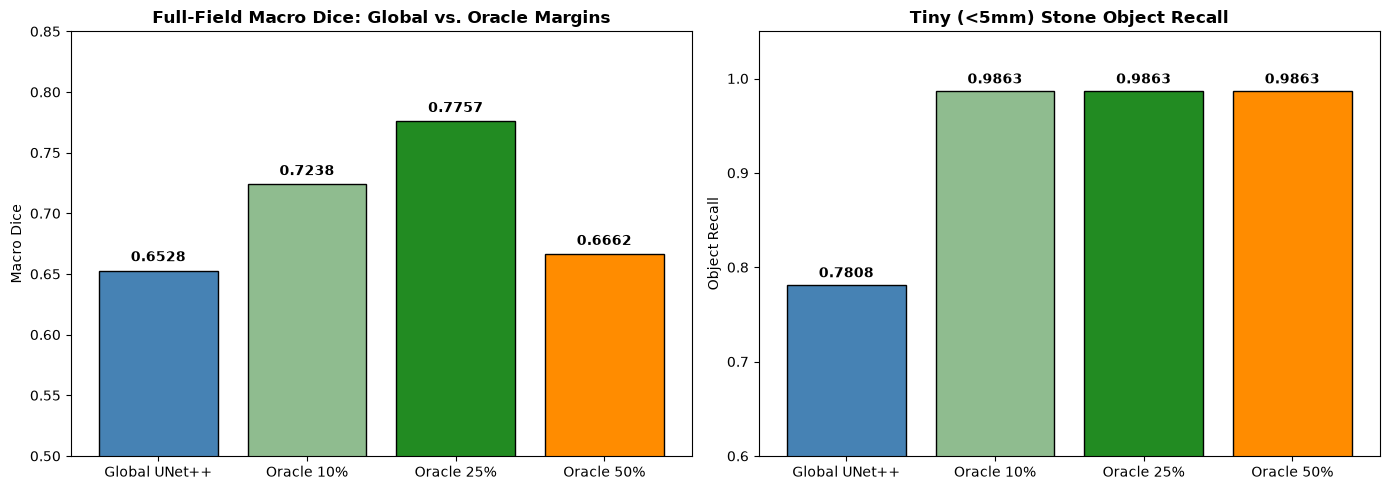

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Macro Dice comparison
methods = df_sum['Method'].tolist()
dices = df_sum['Macro_Dice'].tolist()
colors = ['steelblue', 'darkseagreen', 'forestgreen', 'darkorange']

bars1 = axes[0].bar(methods, dices, color=colors, edgecolor='black')
axes[0].set_title('Full-Field Macro Dice: Global vs. Oracle Margins', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Macro Dice')
axes[0].set_ylim(0.5, 0.85)
for bar in bars1:
    y = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, y + 0.005, f"{y:.4f}", ha='center', va='bottom', fontweight='bold')

# Plot 2: Tiny Stone Recall comparison
tiny_rec = df_sum['Tiny_Recall'].tolist()
bars2 = axes[1].bar(methods, tiny_rec, color=colors, edgecolor='black')
axes[1].set_title('Tiny (<5mm) Stone Object Recall', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Object Recall')
axes[1].set_ylim(0.6, 1.05)
for bar in bars2:
    y = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, y + 0.005, f"{y:.4f}", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
fig_dir = 'reports/figures/retrospective/phase12_oracle' if os.path.exists('reports') else '../../reports/figures/retrospective/phase12_oracle'
os.makedirs(fig_dir, exist_ok=True)
plt.savefig(os.path.join(fig_dir, 'oracle_headroom_comparison.png'), dpi=200, bbox_inches='tight')
display(fig)
plt.close(fig)


## Section B: Oracle ROI Qualitative Visual Evidence
Below is the authoritative multi-panel qualitative figure from Phase 12 (`reports/qualitative/phase12_oracle_roi/phase12_global_vs_oracle_panel.png`) illustrating:
1. **Original full-field radiograph**
2. **Global UNet++ prediction vs. ground truth**
3. **Oracle crop bounding box and local magnification**
4. **Restored regional prediction achieving sharp stone boundary recovery**


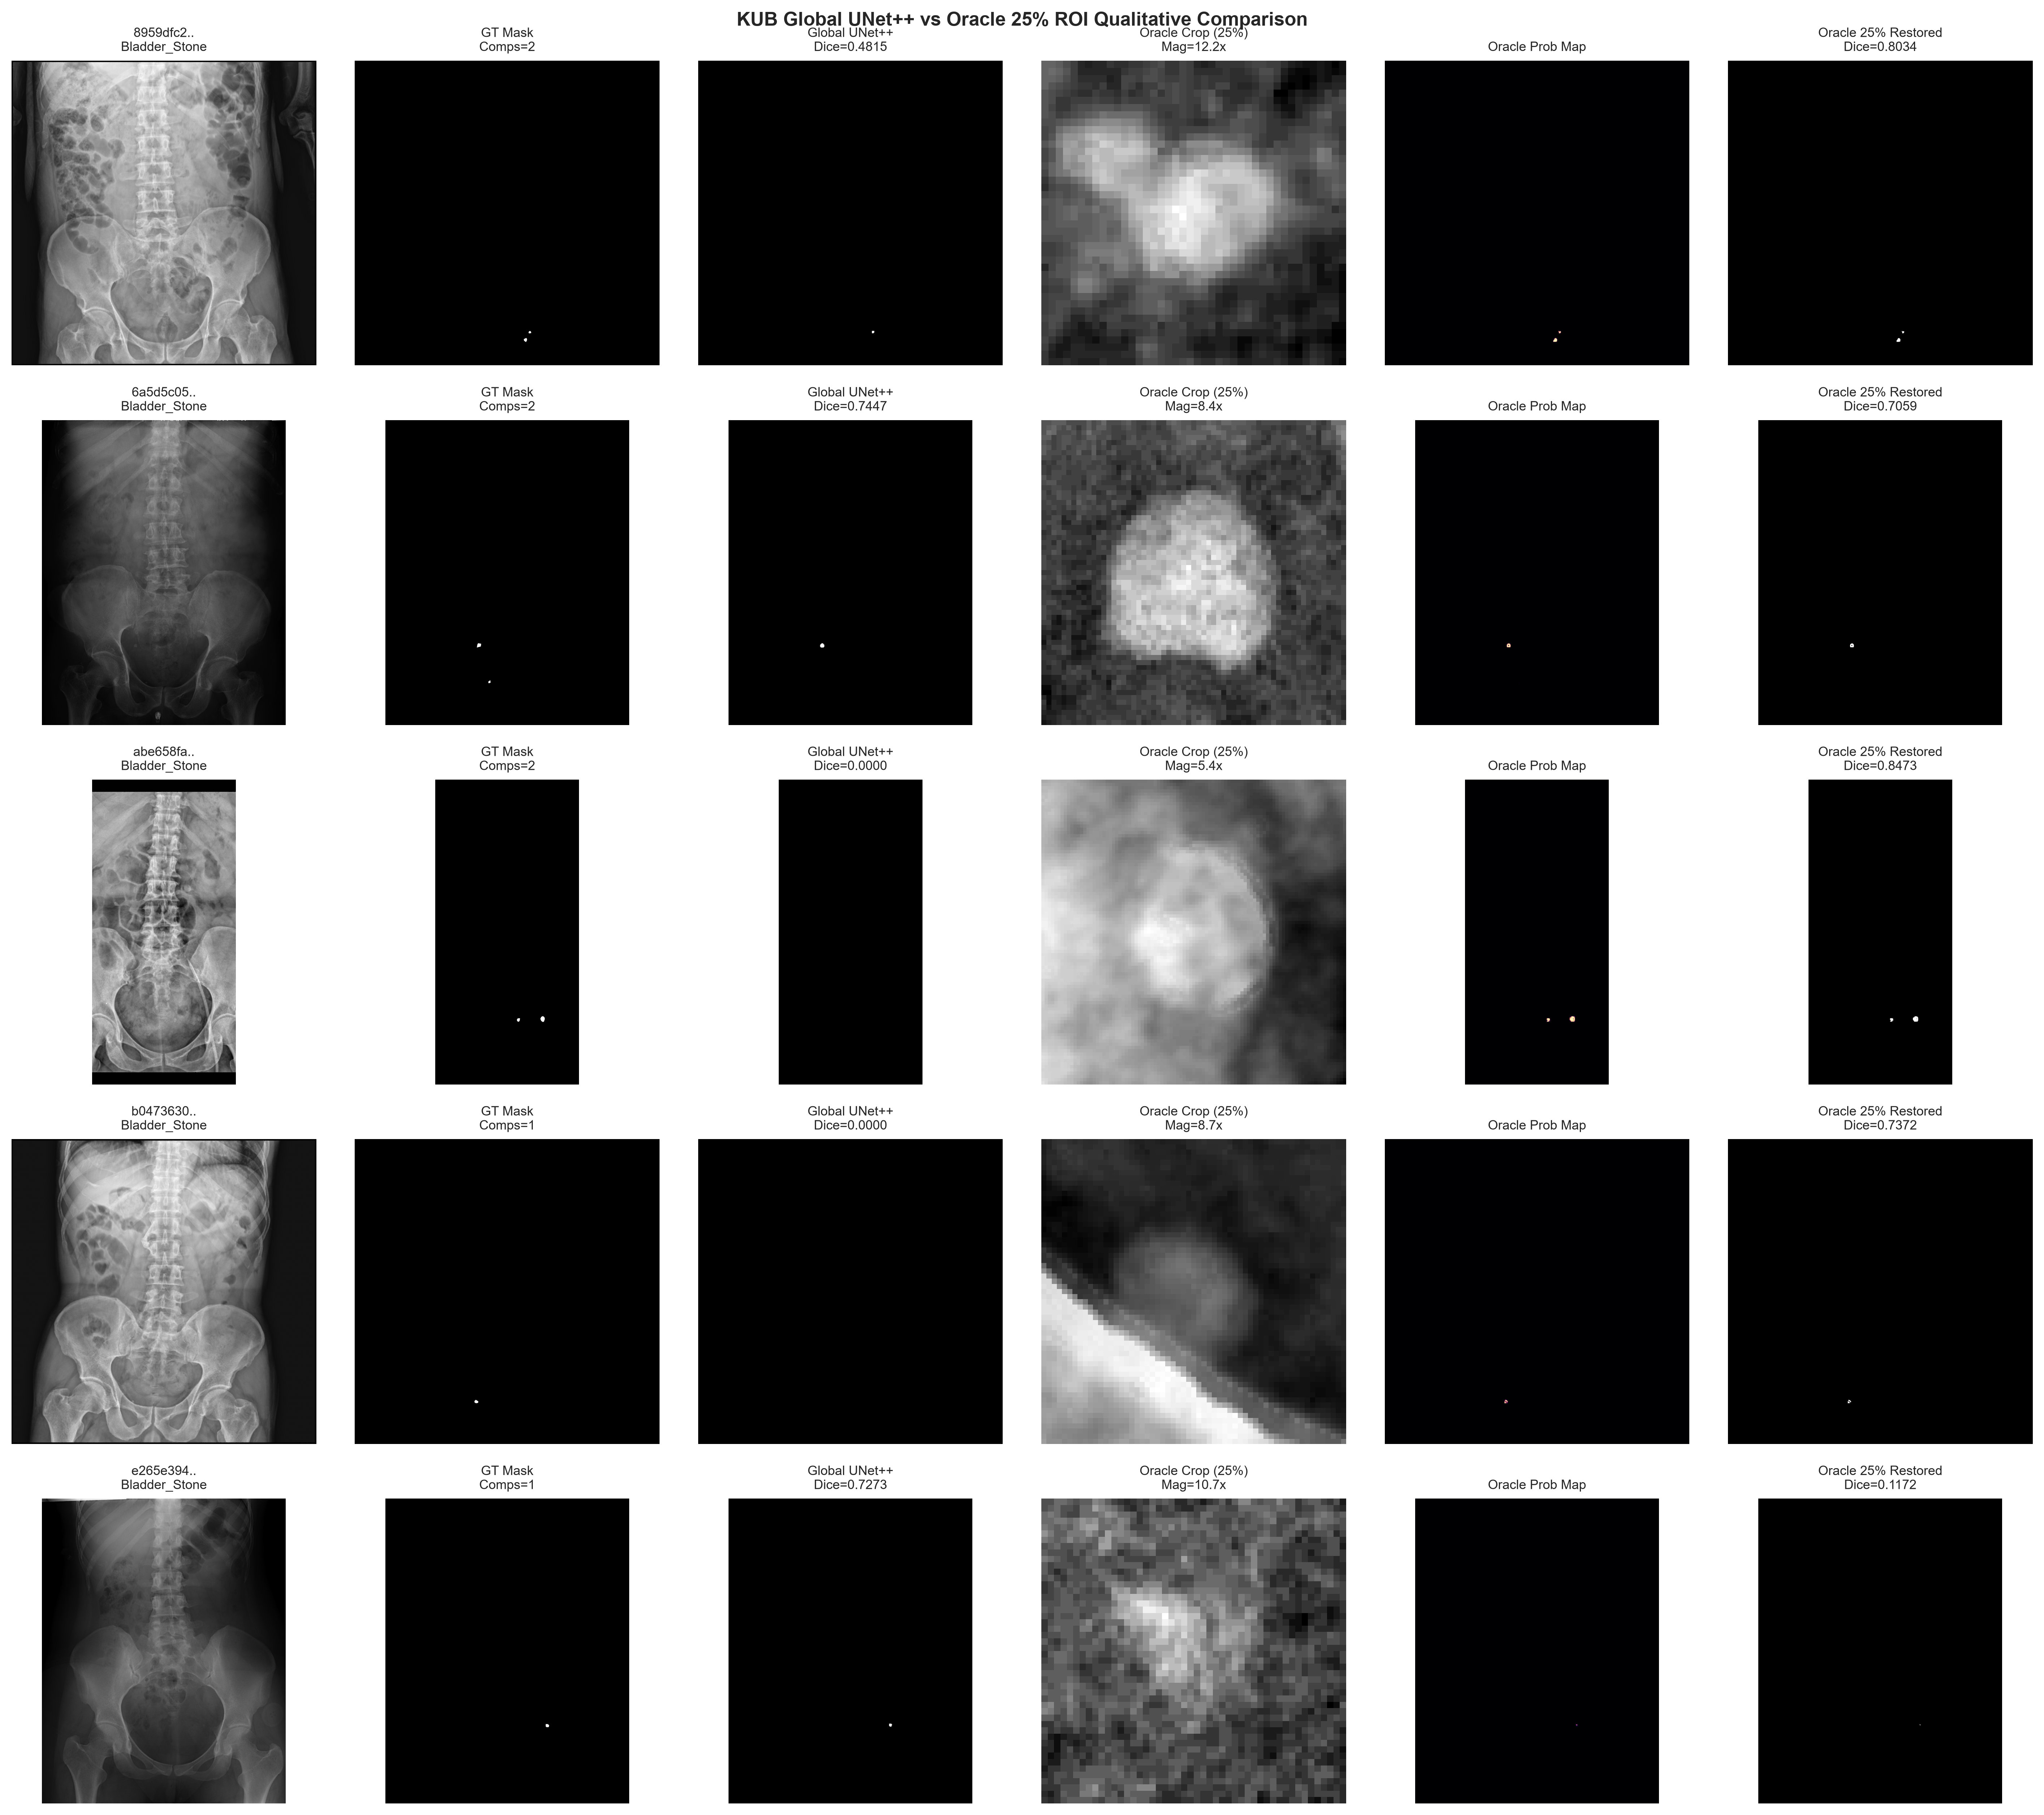

In [3]:
p_panel = 'reports/qualitative/phase12_oracle_roi/phase12_global_vs_oracle_panel.png' if os.path.exists('reports/qualitative/phase12_oracle_roi/phase12_global_vs_oracle_panel.png') else '../../reports/qualitative/phase12_oracle_roi/phase12_global_vs_oracle_panel.png'
if os.path.exists(p_panel):
    display(Image(filename=p_panel))
else:
    print('Qualitative panel path:', p_panel)


## Section C: Scientific Interpretation & The Gate to Phase 13
**Critical Scientific Insight:**
- Oracle ROI demonstrates that the standard UNet++ architecture has ample capacity to segment tiny stones when given adequate effective pixel resolution.
- However, **Oracle bounding boxes are clinical cheat codes** (they require ground truth).
- Therefore, to realize these gains in a practical clinical deployment, we must develop a **GT-free learned localizer** that can autonomously propose these candidate regions of interest.

This directly authorized **Phase 13 (Predicted ROI Localization)**.
